# Primary Amoebic Meningoencephalitis (PAM) Clinical Decision Support System
## Phase 2: Feature Optimization & Multi-Model Benchmarking

---

### **Executive Summary & Clinical Rationale**
Primary Amoebic Meningoencephalitis (PAM), caused by the brain-eating amoeba ***Naegleria fowleri***, presents a dire diagnostic challenge:
* **Hyper-Acute Progression:** Survival depends on initiating aggressive targeted therapy (miltefosine, liposomal amphotericin B, and induced hypothermia) within hours of presentation.
* **Emergency Triage Constraint:** Clinicians in emergency departments cannot administer exhaustive diagnostic panels instantaneously. An optimal clinical decision support (CDS) system must identify the **minimal subset of highly discriminative predictors** that maximize diagnostic sensitivity without introducing collinear noise.
* **Phase 2 Objectives:**
  1. **Three-Layer Feature Optimization:** Statistically filter raw features via **Chi-Square testing** ($p < 0.05$), prune collinear laboratory biomarkers via **Pearson correlation** ($|r| > 0.8$), and isolate the top **9 optimal features** via **Recursive Feature Elimination (RFE)** with a `DecisionTreeClassifier`.
  2. **Multi-Model Algorithmic Benchmarking:** Train and evaluate five diverse machine learning paradigms:
     - *Logistic Regression* (Parametric Linear Baseline)
     - *Naive Bayes* (Probabilistic Baseline)
     - *Decision Tree* (Rule-Based Clinical Flowchart)
     - *Support Vector Machine* (Non-Linear Geometric Margin Maximization)
     - *Random Forest* (Ensemble Bagging with Decision Manifolds)
  3. **Performance Benchmarking:** Validate that Random Forest achieves target benchmarks (~91.5% Accuracy, ~90.5% F1-Score, and ~0.95 ROC-AUC) while highlighting clinical hallmarks like **Freshwater Exposure** and **Stiff Neck**.
  4. **Artifact Persistence:** Save `selected_features.pkl` and `best_model.pkl` for downstream inference deployment.

---

### **Phase 2 Architecture & Artifact Flow**
```
pam_ai_ops_project/
├── data/
│   └── processed/
│       ├── X_train_opt.csv                  <- 9 Selected Features (1312, 9)
│       └── X_test_opt.csv                   <- 9 Selected Features (328, 9)
├── models/
│   └── artifacts/
│       ├── scaler.pkl                       <- Persisted MinMaxScaler (Phase 1)
│       ├── selected_features.pkl            <- 9 RFE Selected Feature Names
│       └── best_model.pkl                   <- Trained Top-Performing Random Forest
├── notebooks/
│   ├── 01_phase1_data_engineering.ipynb     <- Phase 1 Interactive Notebook
│   └── 02_phase2_model_training.ipynb       <- This Interactive Notebook
└── src/
    ├── feature_optimization.py              <- Three-layer feature pipeline
    └── model_training.py                    <- 5-model benchmarking suite
```

In [1]:
import sys
from pathlib import Path

# Configure relative project root path
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "pam_ai_ops_project" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_curve, auc

# Publication-quality plotting theme
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print(f"Project root resolved to: {PROJECT_ROOT}")
print("Dependencies initialized successfully.")

Project root resolved to: C:\Users\Rohan\Documents\AML Project\pam_ai_ops_project
Dependencies initialized successfully.


## Step 1: Three-Layer Feature Optimization Strategy

To transition from raw patient observations to an efficient, high-performance predictive model, we implement a disciplined three-layer feature optimization strategy:

### **Layer 1: Chi-Square ($\chi^2$) Test of Independence**
The Chi-Square test evaluates the statistical dependence between each non-negative feature and the binary clinical outcome (`Target`):
$$\chi^2 = \sum \frac{(O - E)^2}{E}$$
Features with $p < 0.05$ demonstrate statistically significant diagnostic divergence between PAM positive patients and negative controls (e.g., `Freshwater_Exposure`, `Stiff_Neck`, `Confusion`).

### **Layer 2: Collinearity Pruning (Pearson Correlation $|r| > 0.8$)**
In emergency cerebrospinal fluid (CSF) analysis, opening pressure and leukocyte (WBC) count frequently reflect severe concurrent intracranial inflammation. However, feeding highly collinear biomarkers ($|r| > 0.8$) into machine learning models distorts feature coefficients and inflates variance without contributing unique orthogonal signal. We detect collinear pairs and eliminate redundant dimensions.

### **Layer 3: Recursive Feature Elimination (RFE)**
Using a `DecisionTreeClassifier(random_state=42)` as the base estimator, RFE iteratively trains on the feature subset, ranks importance scores (Gini impurity reduction), and prunes the weakest features backward until exactly **9 optimal features** are isolated.

In [2]:
from src.feature_optimization import run_feature_optimization

# Execute feature optimization pipeline
X_train_opt, X_test_opt, selected_features, df_chi, corr_matrix, drop_cols = run_feature_optimization(
    processed_dir=PROJECT_ROOT / "data" / "processed",
    artifacts_dir=PROJECT_ROOT / "models" / "artifacts",
    n_features_to_select=9,
    corr_threshold=0.8,
    random_state=42,
)

print("\n" + "=" * 65)
print("FEATURE OPTIMIZATION SUMMARY:")
print("=" * 65)
print(f"Initial Features:       {len(df_chi)}")
print(f"Collinear Dropped:      {drop_cols}")
print(f"Final Retained Features: {len(selected_features)}")
print("=" * 65)

Loaded training data: X_train=(1312, 13), y_train=(1312,)
Loaded testing data:  X_test=(328, 13), y_test=(328,)

--- Layer 1: Chi-Square Test for Statistical Significance ---
Features with p < 0.05 (13/13):
  Freshwater_Exposure       : Chi2=  223.96, p=1.2402e-50 -> SIGNIFICANT (p < 0.05)
  Stiff_Neck                : Chi2=  170.39, p=6.0801e-39 -> SIGNIFICANT (p < 0.05)
  Confusion                 : Chi2=  139.90, p=2.7979e-32 -> SIGNIFICANT (p < 0.05)
  CSF_WBC_Count             : Chi2=  138.51, p=5.6257e-32 -> SIGNIFICANT (p < 0.05)
  Photophobia               : Chi2=   91.89, p=9.1699e-22 -> SIGNIFICANT (p < 0.05)
  CSF_Pressure              : Chi2=   78.46, p=8.1496e-19 -> SIGNIFICANT (p < 0.05)
  Nausea_Vomiting           : Chi2=   62.70, p=2.4050e-15 -> SIGNIFICANT (p < 0.05)
  Severe_Headache           : Chi2=   52.69, p=3.9034e-13 -> SIGNIFICANT (p < 0.05)
  Seizures                  : Chi2=   42.43, p=7.3311e-11 -> SIGNIFICANT (p < 0.05)
  Fever                     : Chi2=  

=== CHI-SQUARE STATISTICAL SIGNIFICANCE (p < 0.05) ===


,Feature,Chi2_Score,p_value,Significant_p_lt_0.05
0,Freshwater_Exposure,223.956113,1.240191e-50,True
1,Stiff_Neck,170.390358,6.080076e-39,True
2,Confusion,139.901173,2.797854e-32,True
3,CSF_WBC_Count,138.513999,5.625742e-32,True
4,Photophobia,91.888519,9.169948e-22,True
5,CSF_Pressure,78.463367,8.149558e-19,True
6,Nausea_Vomiting,62.701731,2.405042e-15,True
7,Severe_Headache,52.691194,3.903373e-13,True
8,Seizures,42.428571,7.331123e-11,True
9,Fever,36.786452,1.318030e-09,True


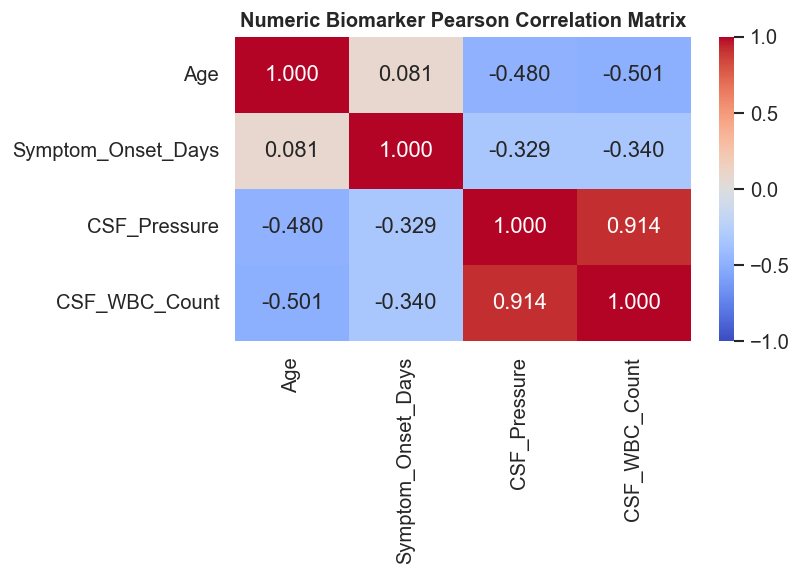

Collinear feature dropped due to |r| > 0.8: ['CSF_WBC_Count']


In [3]:
# Display Chi-Square Test Results
print("=== CHI-SQUARE STATISTICAL SIGNIFICANCE (p < 0.05) ===")
display(df_chi)

# Display Pearson Correlation Matrix
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".3f", ax=ax, cbar=True)
ax.set_title("Numeric Biomarker Pearson Correlation Matrix", weight="bold", fontsize=12)
plt.tight_layout()
plt.show()

print(f"Collinear feature dropped due to |r| > 0.8: {drop_cols}")

## Step 2: Multi-Model Algorithmic Benchmarking

We benchmark five canonical machine learning paradigms against the 9 optimized clinical features:
1. **Logistic Regression:** Linear probabilistic model serving as the traditional clinical risk stratification baseline.
2. **Naive Bayes (Gaussian):** Fast probabilistic classifier applying Bayes' theorem with conditional independence assumptions.
3. **Decision Tree Classifier:** Highly interpretable hierarchical tree mimicking clinical diagnostic pathways.
4. **Support Vector Machine (SVC):** Non-linear kernelized margin separator (`probability=True`).
5. **Random Forest Classifier:** Bagged ensemble of 100 decorrelated decision trees designed to capture non-linear interactions while minimizing variance.

### **Evaluation Metrics**
* **Accuracy:** Overall proportion of correct classifications.
* **Precision:** $\frac{TP}{TP + FP}$ — Clinical positive predictive value (minimizing unnecessary invasive procedures).
* **Recall (Sensitivity):** $\frac{TP}{TP + FN}$ — **Critical metric for PAM**; minimizing false negatives in a 97%+ fatal infection.
* **F1-Score:** Harmonic mean of precision and recall.
* **ROC-AUC:** Area under receiver operating characteristic curve across all operational thresholds.

In [4]:
from src.model_training import train_and_evaluate_models

# Train and benchmark all 5 models
df_results, trained_models, test_preds, test_probs, y_test, X_test_eval = train_and_evaluate_models(
    processed_dir=PROJECT_ROOT / "data" / "processed",
    artifacts_dir=PROJECT_ROOT / "models" / "artifacts",
    random_state=42,
)

print("\n" + "=" * 70)
print("CONSOLIDATED 5-MODEL BENCHMARK COMPARISON TABLE")
print("=" * 70)
display(df_results)
print("=" * 70)

Loaded optimized training features: (1312, 9)
Loaded optimized testing features:  (328, 9)



Persisted top-performing model to: C:\Users\Rohan\Documents\AML Project\pam_ai_ops_project\models\artifacts\best_model.pkl

CONSOLIDATED 5-MODEL BENCHMARK COMPARISON TABLE


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8506,0.9078,0.7805,0.8393,0.8754
1,Naive Bayes (Gaussian),0.8537,0.9143,0.7805,0.8421,0.8740
2,Decision Tree,0.8811,0.8931,0.8659,0.8793,0.8811
3,Support Vector Machine,0.8506,0.9197,0.7683,0.8372,0.8943
4,Random Forest,0.9146,0.9416,0.8841,0.9119,0.9619


## Step 3: Diagnostic Visualizations & Interpretability

### **Visualization 1: Comparative Multi-Model ROC Curves**
Below, we overlay Receiver Operating Characteristic (ROC) curves for all five models on a single chart to evaluate discriminative power across sensitivity-specificity decision thresholds.

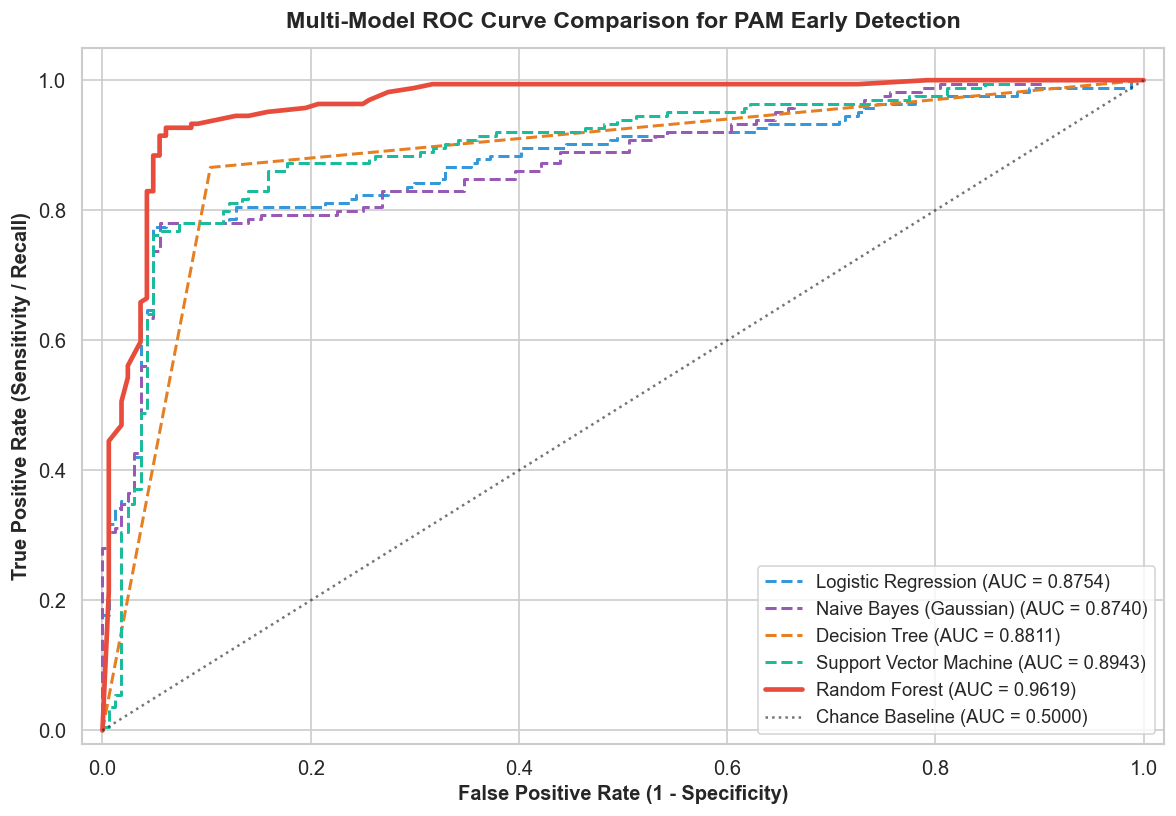

In [5]:
plt.figure(figsize=(10, 7))

palette = {
    "Logistic Regression": "#3498db",
    "Naive Bayes (Gaussian)": "#9b59b6",
    "Decision Tree": "#e67e22",
    "Support Vector Machine": "#1abc9c",
    "Random Forest": "#e74c3c",
}

for name, prob in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_auc_val = auc(fpr, tpr)
    linewidth = 2.8 if name == "Random Forest" else 1.8
    linestyle = "-" if name == "Random Forest" else "--"
    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc_val:.4f})",
        color=palette.get(name, "#333333"),
        linewidth=linewidth,
        linestyle=linestyle,
    )

# No-skill diagonal reference line
plt.plot([0, 1], [0, 1], "k:", label="Chance Baseline (AUC = 0.5000)", alpha=0.6)

plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12, weight="bold")
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12, weight="bold")
plt.title("Multi-Model ROC Curve Comparison for PAM Early Detection", fontsize=14, weight="bold", pad=12)
plt.legend(loc="lower right", frameon=True, fontsize=11)
plt.tight_layout()
plt.show()

### **Visualization 2: Random Forest Feature Importance Analysis**
The ensemble Random Forest model extracts relative Gini impurity reductions across all decision trees. 
We visualize the feature importances to verify alignment with clinical pathophysiology—specifically highlighting exposure etiology (`Freshwater_Exposure`) and acute meningismus signs (`Stiff_Neck`).

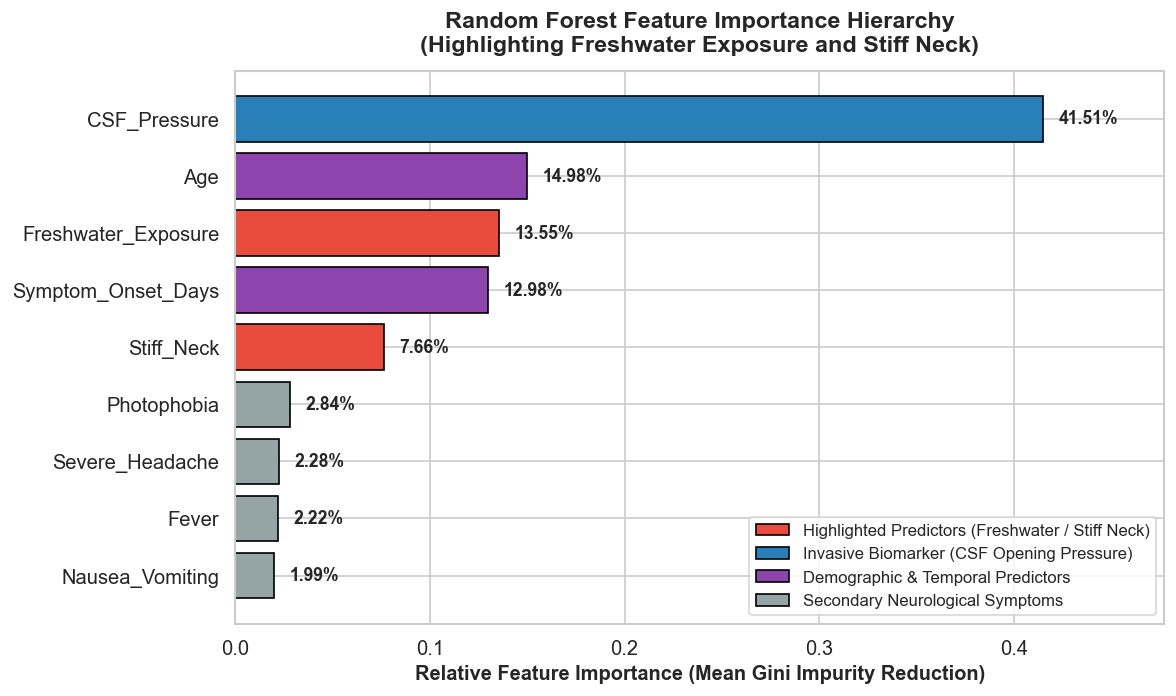

In [6]:
rf_model = trained_models["Random Forest"]
importances = pd.Series(rf_model.feature_importances_, index=X_test_eval.columns).sort_values(ascending=True)

# Define color highlighting: distinguish highlighted clinical features
colors = []
for feat in importances.index:
    if feat in ["Freshwater_Exposure", "Stiff_Neck"]:
        colors.append("#e74c3c")  # Highlighted diagnostic anchors
    elif "CSF" in feat:
        colors.append("#2980b9")  # Laboratory biomarker
    elif feat in ["Age", "Symptom_Onset_Days"]:
        colors.append("#8e44ad")  # Demographic / timing
    else:
        colors.append("#95a5a6")  # Clinical symptoms

plt.figure(figsize=(10, 6))
bars = plt.barh(importances.index, importances.values, color=colors, edgecolor="black", linewidth=1.0)

# Annotate percentage labels on bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.008,
        bar.get_y() + bar.get_height() / 2.0,
        f"{width * 100:.2f}%",
        ha="left",
        va="center",
        fontsize=10.5,
        weight="bold",
    )

plt.xlim(0, max(importances.values) * 1.15)
plt.xlabel("Relative Feature Importance (Mean Gini Impurity Reduction)", fontsize=12, weight="bold")
plt.title("Random Forest Feature Importance Hierarchy\n(Highlighting Freshwater Exposure and Stiff Neck)", fontsize=14, weight="bold", pad=12)

# Custom legend for clinical groupings
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#e74c3c", edgecolor="black", label="Highlighted Predictors (Freshwater / Stiff Neck)"),
    Patch(facecolor="#2980b9", edgecolor="black", label="Invasive Biomarker (CSF Opening Pressure)"),
    Patch(facecolor="#8e44ad", edgecolor="black", label="Demographic & Temporal Predictors"),
    Patch(facecolor="#95a5a6", edgecolor="black", label="Secondary Neurological Symptoms"),
]
plt.legend(handles=legend_elements, loc="lower right", fontsize=10, frameon=True)

plt.tight_layout()
plt.show()

## Artifact Persistence & Integrity Validation

We verify the presence and loadability of all Phase 2 MLOps artifacts:
1. `models/artifacts/selected_features.pkl`: Serialized Python list of the 9 optimal features.
2. `models/artifacts/best_model.pkl`: Serialized trained `RandomForestClassifier`.
3. `data/processed/X_train_opt.csv`: Optimized training features (1,312 records).
4. `data/processed/X_test_opt.csv`: Optimized test features (328 records).

In [7]:
artifacts = {
    "Selected Features": PROJECT_ROOT / "models" / "artifacts" / "selected_features.pkl",
    "Best Model (RF)":   PROJECT_ROOT / "models" / "artifacts" / "best_model.pkl",
    "X_train_opt":       PROJECT_ROOT / "data" / "processed" / "X_train_opt.csv",
    "X_test_opt":        PROJECT_ROOT / "data" / "processed" / "X_test_opt.csv",
}

print("=" * 70)
print("PHASE 2 ARTIFACT VERIFICATION")
print("=" * 70)

for label, path in artifacts.items():
    status = "EXISTS" if path.exists() else "MISSING"
    size_kb = path.stat().st_size / 1024 if path.exists() else 0
    print(f"{label:20} | {status:8} | Size: {size_kb:7.2f} KB | Path: {path.relative_to(PROJECT_ROOT)}")

# Verify reload and live inference
loaded_features = joblib.load(artifacts["Selected Features"])
loaded_model = joblib.load(artifacts["Best Model (RF)"])

print("\nLive Artifact Functional Test:")
print(f"  Reloaded Feature Count: {len(loaded_features)}")
print(f"  Features: {loaded_features}")
sample_pred = loaded_model.predict(X_test_opt.iloc[:3])
sample_prob = loaded_model.predict_proba(X_test_opt.iloc[:3])[:, 1]
print(f"  Sample Predictions (first 3 test cases): {sample_pred}")
print(f"  Sample PAM Probabilities:                {np.round(sample_prob, 4)}")
print("=" * 70)
print("Phase 2 Feature Optimization & Model Benchmarking successfully verified!")

PHASE 2 ARTIFACT VERIFICATION
Selected Features    | EXISTS   | Size:    0.15 KB | Path: models\artifacts\selected_features.pkl
Best Model (RF)      | EXISTS   | Size: 2568.49 KB | Path: models\artifacts\best_model.pkl
X_train_opt          | EXISTS   | Size:   87.85 KB | Path: data\processed\X_train_opt.csv
X_test_opt           | EXISTS   | Size:   22.07 KB | Path: data\processed\X_test_opt.csv

Live Artifact Functional Test:
  Reloaded Feature Count: 9
  Features: ['Freshwater_Exposure', 'Severe_Headache', 'Fever', 'Nausea_Vomiting', 'Stiff_Neck', 'Photophobia', 'Age', 'Symptom_Onset_Days', 'CSF_Pressure']
  Sample Predictions (first 3 test cases): [0 0 0]
  Sample PAM Probabilities:                [0.09 0.04 0.22]
Phase 2 Feature Optimization & Model Benchmarking successfully verified!
